# Mental Health Project: Review, Cleaning, and Modeling Workflow

This notebook rebuilds the project in a cleaner university-style workflow.

Goals:
- review the raw dataset honestly
- create a documented cleaned-data stage
- avoid preprocessing leakage during modeling
- compare Logistic Regression, Random Forest, and HistGradientBoosting fairly


In [ ]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

DATA_PATH = Path("data/raw/mental_health.csv")
CLEANED_PATH = Path("data/processed/mental_health_cleaned.csv")
RANDOM_STATE = 42

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print(f"Rows: {df_raw.shape[0]}")
print(f"Columns: {df_raw.shape[1]}")
df_raw.head()


Rows: 10000
Columns: 51


,Age,Gender,Country,Education,Marital_Status,Income_Level,Employment_Status,Work_Hours_Per_Week,Remote_Work,Job_Satisfaction,Work_Stress_Level,Work_Life_Balance,Ever_Bullied_At_Work,Company_Mental_Health_Support,Exercise_Per_Week,Sleep_Hours_Night,Caffeine_Drinks_Day,Alcohol_Frequency,Smoking,Screen_Time_Hours_Day,Social_Media_Hours_Day,Hobby_Time_Hours_Week,Diet_Quality,Financial_Stress,Feeling_Sad_Down,Loss_Of_Interest,Sleep_Trouble,Fatigue,Poor_Appetite_Or_Overeating,Feeling_Worthless,Concentration_Difficulty,Anxious_Nervous,Panic_Attacks,Mood_Swings,Irritability,Obsessive_Thoughts,Compulsive_Behavior,Self_Harm_Thoughts,Suicidal_Thoughts,Family_History_Mental_Illness,Previously_Diagnosed,Ever_Sought_Treatment,On_Therapy_Now,On_Medication,Trauma_History,Social_Support,Close_Friends_Count,Feel_Understood,Loneliness,Discuss_Mental_Health,Has_Mental_Health_Issue
0,40,Male,USA,Some College,Single,Middle,Full-time,27,No,6,7,7,0,No,1-2 times,6.2,3,Never,Former,8.3,4.8,7,Average,9,8,3,10,5,9,4,4,1,0,9,2,3,0,0,0,1,1,1,0,0,0,9,3,4,6,Sometimes,1
1,33,Male,India,Bachelor,Married,Middle,Unemployed,47,No,6,1,5,0,Not sure,1-2 times,9.6,3,Weekly,Current,8.6,0.0,7,Average,9,1,10,4,9,4,10,6,8,2,5,9,9,3,0,0,0,0,0,0,0,0,3,2,7,7,Sometimes,1
2,42,Male,Other,High School,Single,Low,Full-time,53,No,1,3,8,0,Not sure,3-4 times,7.7,1,Never,Former,11.4,3.0,0,Good,2,4,7,8,8,4,9,10,1,0,9,9,7,6,0,0,0,0,1,0,0,1,5,3,6,9,Sometimes,1
3,53,Male,Germany,Bachelor,Single,Middle,Unemployed,42,No,10,3,5,0,No,Never,6.4,1,Rarely,Former,6.4,2.9,5,Average,1,3,8,10,10,2,2,5,3,1,0,2,3,3,0,0,1,0,0,1,0,0,1,3,10,5,Never,1
4,32,Female,India,Bachelor,Single,High,Student,13,No,4,7,7,1,Not sure,1-2 times,7.7,0,Rarely,Current,7.6,4.0,2,Excellent,8,6,8,4,5,4,5,7,10,1,0,10,10,1,0,0,0,1,0,0,0,0,1,5,1,6,Sometimes,1


## 1. Data Audit

We start from the raw dataset, inspect basic quality, and document what is actually wrong before changing anything.


In [3]:
audit_summary = pd.DataFrame(
    {
        "metric": ["rows", "columns", "total_missing_values", "duplicate_rows"],
        "value": [
            df_raw.shape[0],
            df_raw.shape[1],
            int(df_raw.isna().sum().sum()),
            int(df_raw.duplicated().sum()),
        ],
    }
)
audit_summary


,metric,value
0,rows,10000
1,columns,51
2,total_missing_values,0
3,duplicate_rows,0


In [4]:
df_raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 51 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            10000 non-null  int64  
 1   Gender                         10000 non-null  str    
 2   Country                        10000 non-null  str    
 3   Education                      10000 non-null  str    
 4   Marital_Status                 10000 non-null  str    
 5   Income_Level                   10000 non-null  str    
 6   Employment_Status              10000 non-null  str    
 7   Work_Hours_Per_Week            10000 non-null  int64  
 8   Remote_Work                    10000 non-null  str    
 9   Job_Satisfaction               10000 non-null  int64  
 10  Work_Stress_Level              10000 non-null  int64  
 11  Work_Life_Balance              10000 non-null  int64  
 12  Ever_Bullied_At_Work           10000 non-null  int64  
 13

In [5]:
target_col = "Has_Mental_Health_Issue"
target_counts = df_raw[target_col].value_counts().sort_index()
target_percent = (df_raw[target_col].value_counts(normalize=True).sort_index() * 100).round(2)
target_summary = pd.DataFrame({"count": target_counts, "percent": target_percent})
target_summary.index.name = target_col
target_summary


,count,percent
Has_Mental_Health_Issue,,
0,784,7.84
1,9216,92.16


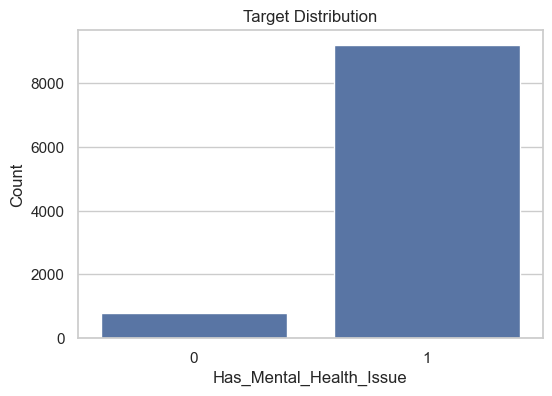

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df_raw, x=target_col, ax=ax)
ax.set_title("Target Distribution")
ax.set_xlabel("Has_Mental_Health_Issue")
ax.set_ylabel("Count")
plt.show()


## 2. Focused EDA

The dataset is already structurally clean, so the EDA should focus on relationships with the target rather than spending too much time on generic summaries.


In [7]:
numeric_eda_cols = [
    "Work_Stress_Level",
    "Financial_Stress",
    "Social_Support",
    "Loneliness",
    "Sleep_Hours_Night",
]

df_raw.groupby(target_col)[numeric_eda_cols].agg(["mean", "median"]).round(2)


Work_Stress_Level        Financial_Stress         \
                                     mean median             mean median   
Has_Mental_Health_Issue                                                    
0                                    4.95    5.0             5.03    5.0   
1                                    5.54    6.0             5.52    6.0   

                        Social_Support        Loneliness         \
                                  mean median       mean median   
Has_Mental_Health_Issue                                           
0                                 5.93    6.0       5.05    5.0   
1                                 5.42    5.0       5.48    5.0   

                        Sleep_Hours_Night         
                                     mean median  
Has_Mental_Health_Issue                           
0                                    6.81    6.8  
1                                    6.82    6.8

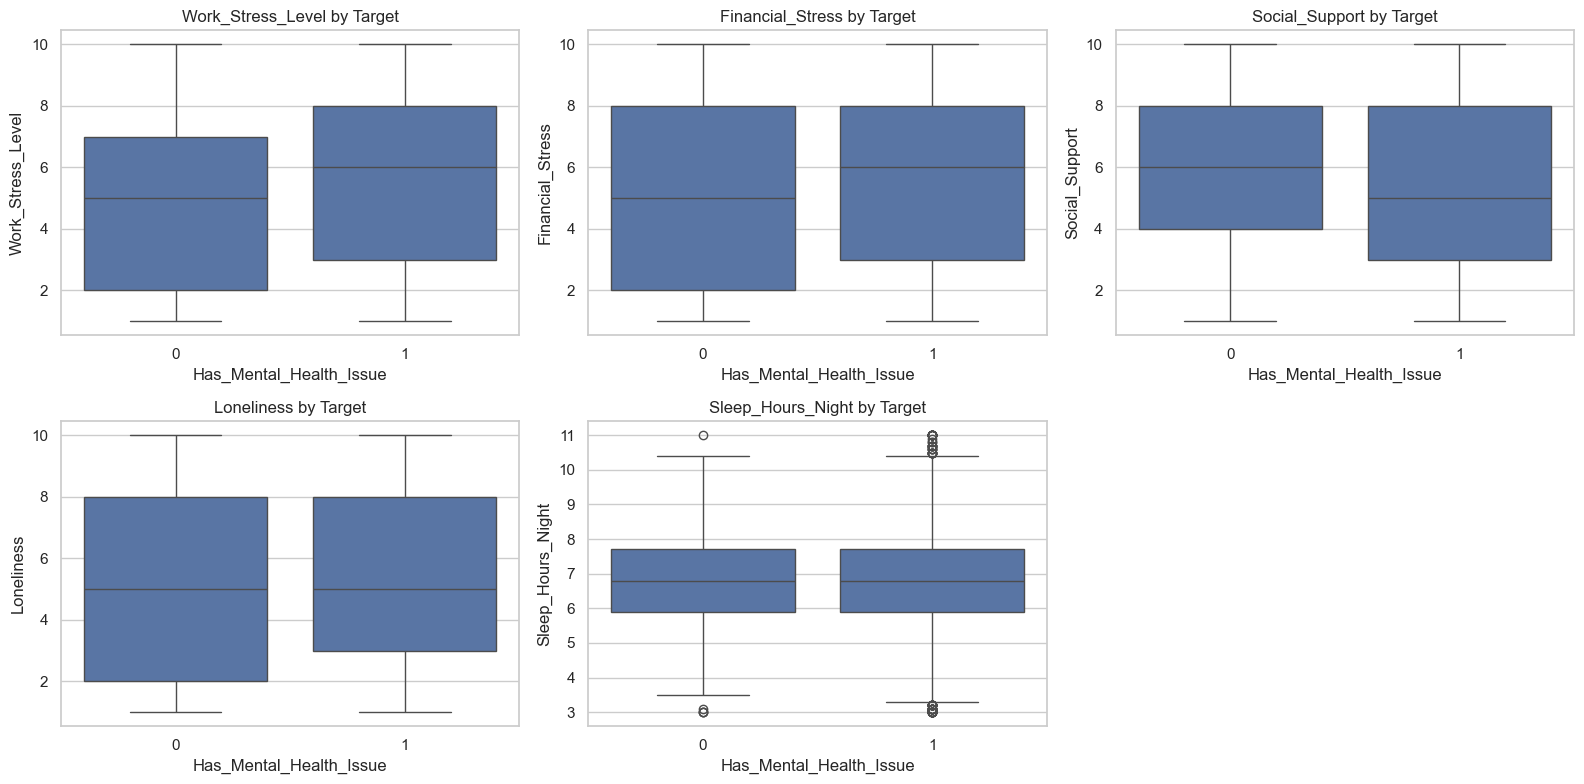

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()
for ax, col in zip(axes, numeric_eda_cols):
    sns.boxplot(data=df_raw, x=target_col, y=col, ax=ax)
    ax.set_title(f"{col} by Target")
for ax in axes[len(numeric_eda_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


In [9]:
categorical_eda_cols = [
    "Employment_Status",
    "Exercise_Per_Week",
    "Company_Mental_Health_Support",
    "Smoking",
    "Previously_Diagnosed",
    "On_Therapy_Now",
]

for col in categorical_eda_cols:
    display(pd.crosstab(df_raw[col], df_raw[target_col], normalize="index").round(3))


Has_Mental_Health_Issue,0,1
Employment_Status,,
Full-time,0.077,0.923
Part-time,0.084,0.916
Self-employed,0.079,0.921
Student,0.073,0.927
Unemployed,0.084,0.916


Has_Mental_Health_Issue,0,1
Exercise_Per_Week,,
1-2 times,0.081,0.919
3-4 times,0.075,0.925
5+ times,0.082,0.918
Never,0.076,0.924


Has_Mental_Health_Issue,0,1
Company_Mental_Health_Support,,
No,0.081,0.919
Not sure,0.077,0.923
Yes,0.074,0.926


Has_Mental_Health_Issue,0,1
Smoking,,
Current,0.071,0.929
Former,0.071,0.929
Never,0.083,0.917


Has_Mental_Health_Issue,0,1
Previously_Diagnosed,,
0,0.081,0.919
1,0.071,0.929


Has_Mental_Health_Issue,0,1
On_Therapy_Now,,
0,0.079,0.921
1,0.074,0.926


The diagnosis/treatment-related variables are kept in EDA because they help explain the dataset. They will be excluded from the predictive feature matrix later because they are very close to already knowing the outcome.


## 3. Cleaning Stage

This stage produces an audited cleaned dataset. We only apply raw-data cleaning decisions here. Model-specific transformations such as encoding and scaling are reserved for the modeling pipeline.


In [10]:
df_cleaned = df_raw.copy()

for col in df_cleaned.select_dtypes(include=["object", "string"]).columns:
    df_cleaned[col] = df_cleaned[col].astype(str).str.strip()

outlier_review_cols = [
    "Age",
    "Work_Hours_Per_Week",
    "Sleep_Hours_Night",
    "Caffeine_Drinks_Day",
    "Screen_Time_Hours_Day",
    "Social_Media_Hours_Day",
    "Hobby_Time_Hours_Week",
    "Close_Friends_Count",
]

outlier_summary = []
for col in outlier_review_cols:
    q1 = df_cleaned[col].quantile(0.25)
    q3 = df_cleaned[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_outliers = int(((df_cleaned[col] < lower) | (df_cleaned[col] > upper)).sum())
    outlier_summary.append(
        {
            "feature": col,
            "q1": round(q1, 2),
            "q3": round(q3, 2),
            "lower_bound": round(lower, 2),
            "upper_bound": round(upper, 2),
            "n_iqr_outliers": n_outliers,
            "decision": "kept - values remain plausible",
        }
    )

outlier_review = pd.DataFrame(outlier_summary)
outlier_review


,feature,q1,q3,lower_bound,upper_bound,n_iqr_outliers,decision
0,Age,26.0,43.0,0.50,68.50,25,kept - values remain plausible
1,Work_Hours_Per_Week,33.0,46.0,13.50,65.50,94,kept - values remain plausible
2,Sleep_Hours_Night,5.9,7.7,3.20,10.40,84,kept - values remain plausible
3,Caffeine_Drinks_Day,1.0,3.0,-2.00,6.00,46,kept - values remain plausible
4,Screen_Time_Hours_Day,5.0,9.1,-1.15,15.25,36,kept - values remain plausible
5,Social_Media_Hours_Day,1.3,4.7,-3.80,9.80,33,kept - values remain plausible
6,Hobby_Time_Hours_Week,2.0,7.0,-5.50,14.50,65,kept - values remain plausible
7,Close_Friends_Count,3.0,5.0,0.00,8.00,217,kept - values remain plausible


In [11]:
cleaning_actions = pd.DataFrame(
    [
        {"check": "Missing values", "result": int(df_raw.isna().sum().sum()), "action": "No imputation needed"},
        {"check": "Duplicate rows", "result": int(df_raw.duplicated().sum()), "action": "No duplicate removal needed"},
        {"check": "String cleanup", "result": "trimmed", "action": "Leading/trailing spaces removed if present"},
        {"check": "Outlier review", "result": "reviewed", "action": "Plausible extremes retained; no winsorization/removal"},
    ]
)
cleaning_actions


,check,result,action
0,Missing values,0,No imputation needed
1,Duplicate rows,0,No duplicate removal needed
2,String cleanup,trimmed,Leading/trailing spaces removed if present
3,Outlier review,reviewed,Plausible extremes retained; no winsorization/...


In [12]:
df_cleaned.to_csv(CLEANED_PATH, index=False)
print(f"Cleaned dataset saved to: {CLEANED_PATH.resolve()}")
print(df_cleaned.shape)


Cleaned dataset saved to: /Users/youssefsassi/Documents/Data science/data-project/mental_health_cleaned.csv
(10000, 51)


## 4. Modeling Setup

We keep the cleaned dataset for documentation, but the actual modeling workflow still follows split-first, preprocess-second. This avoids leakage.


In [ ]:
proxy_drop_cols = [
    "Previously_Diagnosed",
    "Ever_Sought_Treatment",
    "On_Therapy_Now",
    "On_Medication",
]

ordinal_cols = [
    "Education",
    "Income_Level",
    "Exercise_Per_Week",
    "Diet_Quality",
    "Alcohol_Frequency",
    "Discuss_Mental_Health",
]

nominal_cols = [
    "Gender",
    "Country",
    "Marital_Status",
    "Employment_Status",
    "Remote_Work",
    "Company_Mental_Health_Support",
    "Smoking",
]

ordinal_categories = [
    ["High School", "Some College", "Bachelor", "Master", "PhD"],
    ["Low", "Middle", "High"],
    ["Never", "1-2 times", "3-4 times", "5+ times"],
    ["Poor", "Average", "Good", "Excellent"],
    ["Never", "Rarely", "Weekly", "Daily"],
    ["Never", "Rarely", "Sometimes", "Yes easily"],
]

def make_feature_sets(df):
    y = df[target_col].astype(int)
    X = df.drop(columns=[target_col] + proxy_drop_cols)
    numeric_cols = [
        col for col in X.columns
        if col not in ordinal_cols and col not in nominal_cols
    ]
    return X, y, numeric_cols, ordinal_cols, nominal_cols

def build_preprocessor(scale_numeric, numeric_cols, ordinal_cols, nominal_cols):
    ordinal_steps = [("encoder", OrdinalEncoder(categories=ordinal_categories, handle_unknown="use_encoded_value", unknown_value=-1))]
    if scale_numeric:
        ordinal_steps.append(("scaler", StandardScaler()))
    ordinal_transformer = Pipeline(steps=ordinal_steps)

    numeric_transformer = Pipeline(steps=[("scaler", StandardScaler())]) if scale_numeric else "passthrough"

    return ColumnTransformer(
        transformers=[
            ("ordinal", ordinal_transformer, ordinal_cols),
            ("nominal", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), nominal_cols),
            ("numeric", numeric_transformer, numeric_cols),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )

def evaluate_with_cv(model_name, pipeline, X_train, y_train, cv):
    scoring = {
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc",
        "average_precision": "average_precision",
    }
    cv_results = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        return_train_score=False,
    )
    return {
        "model": model_name,
        "cv_accuracy_mean": cv_results["test_accuracy"].mean(),
        "cv_precision_mean": cv_results["test_precision"].mean(),
        "cv_recall_mean": cv_results["test_recall"].mean(),
        "cv_f1_mean": cv_results["test_f1"].mean(),
        "cv_f1_std": cv_results["test_f1"].std(),
        "cv_roc_auc_mean": cv_results["test_roc_auc"].mean(),
        "cv_pr_auc_mean": cv_results["test_average_precision"].mean(),
    }

def evaluate_on_test(model_name, pipeline, X_train, X_test, y_train, y_test):
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1]
    metrics = {
        "model": model_name,
        "test_accuracy": accuracy_score(y_test, y_pred),
        "test_precision": precision_score(y_test, y_pred, zero_division=0),
        "test_recall": recall_score(y_test, y_pred, zero_division=0),
        "test_f1": f1_score(y_test, y_pred, zero_division=0),
        "test_roc_auc": roc_auc_score(y_test, y_proba),
        "test_pr_auc": average_precision_score(y_test, y_proba),
    }
    report = classification_report(y_test, y_pred, zero_division=0)
    matrix = confusion_matrix(y_test, y_pred)
    return metrics, report, matrix

X, y, numeric_cols, ordinal_cols, nominal_cols = make_feature_sets(df_cleaned)
print(X.shape, y.shape)

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE,
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

linear_preprocessor = build_preprocessor(True, numeric_cols, ordinal_cols, nominal_cols)
tree_preprocessor = build_preprocessor(False, numeric_cols, ordinal_cols, nominal_cols)

models = {
    "Logistic Regression": Pipeline(
        steps=[
            ("preprocessor", linear_preprocessor),
            ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
        ]
    ),
    "Random Forest": Pipeline(
        steps=[
            ("preprocessor", tree_preprocessor),
            (
                "model",
                RandomForestClassifier(
                    n_estimators=300,
                    min_samples_leaf=2,
                    class_weight="balanced",
                    random_state=RANDOM_STATE,
                    n_jobs=1,
                ),
            ),
        ]
    ),
    "HistGradientBoosting": Pipeline(
        steps=[
            ("preprocessor", tree_preprocessor),
            (
                "model",
                HistGradientBoostingClassifier(
                    max_iter=200,
                    learning_rate=0.05,
                    max_depth=6,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    ),
}


In [17]:
cv_rows = []
for model_name, pipeline in models.items():
    cv_rows.append(evaluate_with_cv(model_name, pipeline, X_train, y_train, cv))

cv_results_df = pd.DataFrame(cv_rows).sort_values(["cv_f1_mean", "cv_recall_mean"], ascending=False)
cv_results_display = cv_results_df.copy()
numeric_cv_cols = [col for col in cv_results_display.columns if col != "model"]
cv_results_display[numeric_cv_cols] = cv_results_display[numeric_cv_cols].round(4)
cv_results_display


,model,cv_accuracy_mean,cv_precision_mean,cv_recall_mean,cv_f1_mean,cv_f1_std
2,HistGradientBoosting,0.9218,0.9220,0.9997,0.9593,0.0002
1,Random Forest,0.9216,0.9216,1.0000,0.9592,0.0002
0,Logistic Regression,0.6281,0.9476,0.6315,0.7577,0.0111


In [18]:
best_model_name = cv_results_df.iloc[0]["model"]
best_pipeline = models[best_model_name]
test_metrics, test_report, test_matrix = evaluate_on_test(
    best_model_name,
    best_pipeline,
    X_train,
    X_test,
    y_train,
    y_test,
)

test_metrics_df = pd.DataFrame([test_metrics])
numeric_test_cols = [col for col in test_metrics_df.columns if col != "model"]
test_metrics_df[numeric_test_cols] = test_metrics_df[numeric_test_cols].round(4)
test_metrics_df


,model,test_accuracy,test_precision,test_recall,test_f1
0,HistGradientBoosting,0.9215,0.9215,1.0,0.9591


In [19]:
print(f"Selected model: {best_model_name}")
print("\nClassification report:\n")
print(test_report)

cm_df = pd.DataFrame(test_matrix, index=["Actual 0", "Actual 1"], columns=["Pred 0", "Pred 1"])
cm_df


Selected model: HistGradientBoosting

Classification report:

              precision    recall  f1-score   support

           0       0.00      0.00      0.00       157
           1       0.92      1.00      0.96      1843

    accuracy                           0.92      2000
   macro avg       0.46      0.50      0.48      2000
weighted avg       0.85      0.92      0.88      2000



,Pred 0,Pred 1
Actual 0,0,157
Actual 1,0,1843
